# Comparative Evaluation of Clustering Methods: Imputation, Model Selection and Stability

**Question.** Do the 2,240 colonies in the dataset form distinct groups, and which clustering method recovers them most reliably?

**Approach.** Benchmark imputation methods for the ~10% missing values; screen features on variance and correlation; compare K-Means, Ward hierarchical clustering, Gaussian mixtures and DBSCAN on three internal validity indices; test the stability of each partition with bootstrap resampling; interpret the final segments.

The notebook only orchestrates and reports. All logic lives in `src/` (`preprocessing.py`, `models.py`, `plots.py`).

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score

from src import preprocessing as pp, models as md, plots as pl

pd.set_option("display.precision", 3)
SEED = 42

## 1. Data and missingness

2,240 colonies, 34 attributes. Every attribute has between 8.6% and 11.6% missing values, scattered across rows: only 77 rows (3%) are complete, so dropping incomplete rows would discard most of the data.

In [2]:
raw = pp.load("data/alien_galaxy.csv")
print(raw.shape)
print(f"Complete rows: {raw.dropna().shape[0]} of {len(raw)}")
raw.isna().mean().describe()[["min", "mean", "max"]].to_frame("share missing per column")

(2240, 34)
Complete rows: 77 of 2240


,share missing per column
min,0.086
mean,0.100
max,0.116


## 2. Encoding and domain screening

Identifiers (`Planet_ID`), dates (`Discovery_Date`, `Colonization_Year`, `Last_Contact_Days`) and abstract categorical traits are removed: they describe *when* or *who*, not the colony's economic or environmental profile. `Alien_Civilization_Level` is ordinal and is encoded 1 (Basic) to 5 (PhD).

In [3]:
df = pp.encode(raw)
print(f"{raw.shape[1]} -> {df.shape[1]} columns")

34 -> 22 columns


## 3. Imputation: benchmarking before choosing

Each imputer is scored on values that are actually observed: 5% of observed cells are hidden, imputed back, and compared with the truth (RMSE in standard-deviation units, after z-scoring so that distances are comparable across features).

In [4]:
std = pp.standardize(df)
imputation = pp.masked_imputation_error(std, share=0.05, seed=SEED)
imputation

,method,rmse,mae
0,KNN (k=10),0.872,0.544
1,KNN (k=5),0.896,0.551
2,Mean,1.006,0.738
3,Median,1.070,0.655


KNN imputation with 10 neighbours reconstructs hidden values about 13% more accurately than the column mean, because it borrows information from similar colonies instead of shrinking every gap to the average. It is used below.

In [5]:
imputed = pp.knn_impute(std, k=10)
assert imputed.isna().sum().sum() == 0

## 4. Feature screening

**Near-constant features.** A feature where almost every colony has the same value cannot separate groups, but its rare deviations can dominate distances after min-max scaling. Features whose most frequent value covers more than 90% of rows are removed.

In [6]:
dominance = pp.dominant_value_share(df)
dominance.head(6).to_frame("share of most frequent value")

,share of most frequent value
Technological_Advancements,0.934
Peace_Treaty_Accords,0.933
Military_Engagements,0.928
Terraforming_Initiatives,0.925
Offspring_Colonies,0.577
Civilization_Level,0.502


`Technological_Advancements`, `Peace_Treaty_Accords`, `Military_Engagements` and `Terraforming_Initiatives` are dropped. `Technological_Advancements` matters most: it was kept in the original version of this project, and section 6 shows it was driving a spurious DBSCAN cluster.

**Redundancy.** Among the remaining features, strongly correlated pairs ($|r| \geq 0.45$) are inspected so that the final set covers each underlying dimension (production, energy, population, expansion) without over-weighting it.

In [7]:
screened = [c for c in imputed.columns if dominance[c] < 0.9]
pp.correlated_pairs(imputed[screened], threshold=0.45).head(12)

,feature_1,feature_2,r
0,Mineral_Extraction_Tons,Exploration_Missions,0.735
1,Resource_Mining_Operations,Liquid_Energy_Consumption_Terawatts,0.653
2,Exploration_Missions,Liquid_Energy_Consumption_Terawatts,0.642
3,Food_Production_Tons,Biological_Research_Units,0.606
4,Exploration_Missions,Alien_Population_Count,0.592
5,Biological_Research_Units,Resource_Allocation_Credits,0.588
6,Liquid_Energy_Consumption_Terawatts,Alien_Population_Count,0.587
7,Food_Production_Tons,Resource_Allocation_Credits,0.585
8,Mineral_Extraction_Tons,Biological_Research_Units,0.584
9,Mineral_Extraction_Tons,Alien_Population_Count,0.581


In [8]:
features = pp.CLUSTERING_FEATURES
X = pp.scale_for_clustering(imputed[features])
print(f"{len(features)} features, {X.shape[0]} colonies")
features

11 features, 2240 colonies


['Food_Production_Tons',
 'Mineral_Extraction_Tons',
 'Resource_Mining_Operations',
 'Resource_Allocation_Credits',
 'CO2_Concentration',
 'Liquid_Energy_Consumption_Terawatts',
 'Offspring_Colonies',
 'Biological_Research_Units',
 'Alien_Population_Count',
 'Exploration_Missions',
 'Civilization_Level']

## 5. Model selection: K-Means, Ward and Gaussian mixtures

Each method is fitted for k = 2 to 8 and scored with three internal indices. No single index is reliable on its own, so agreement between them is what counts.

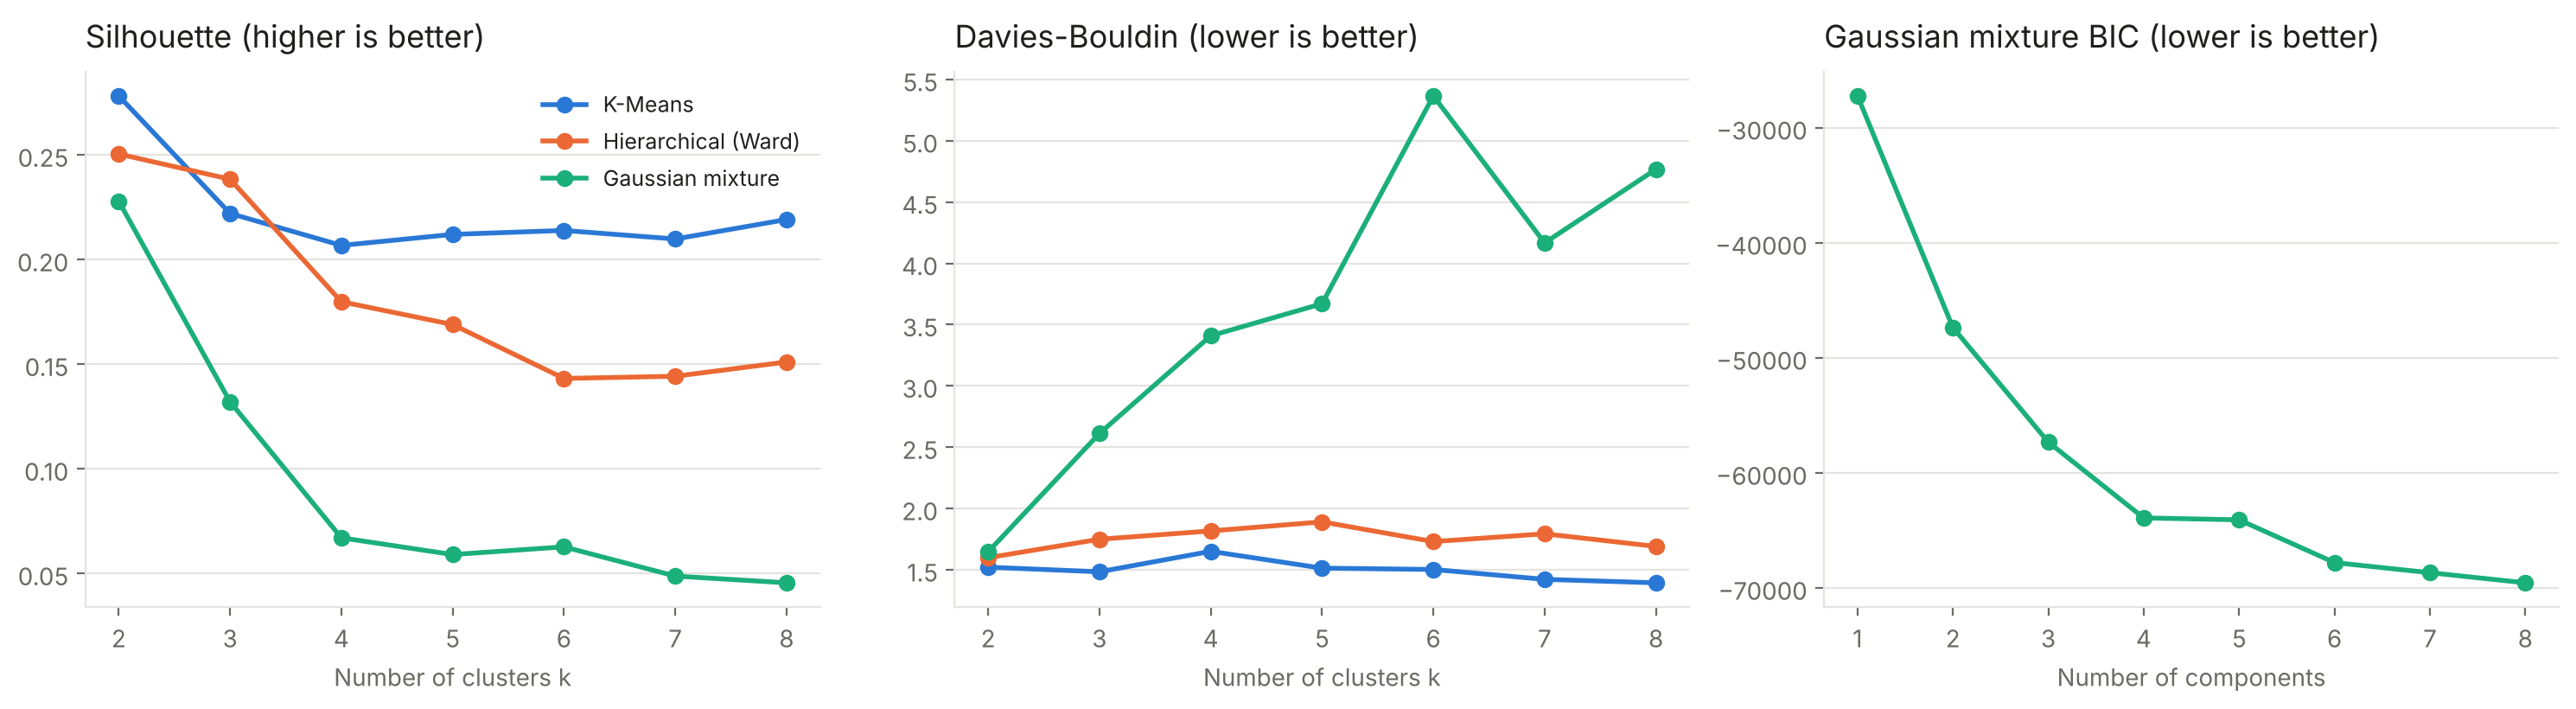

In [9]:
sweep = md.k_sweep(X, ["K-Means", "Hierarchical (Ward)", "Gaussian mixture"], ks=range(2, 9))
bic = md.gmm_bic(X, ks=range(1, 9))
pl.model_selection(sweep, bic, path="images/model_selection.png");

In [10]:
sweep.pivot(index="k", columns="method", values="silhouette")

method,Gaussian mixture,Hierarchical (Ward),K-Means
k,,,
2,0.228,0.250,0.278
3,0.132,0.238,0.222
4,0.067,0.180,0.207
5,0.059,0.169,0.212
6,0.063,0.143,0.214
7,0.049,0.144,0.210
8,0.046,0.151,0.219


- All three methods reach their best silhouette at **k = 2**, and Calinski-Harabasz agrees for every method. Davies-Bouldin drifts slightly lower for K-Means as k grows, but the differences are small next to the drop in silhouette.
- Silhouette never exceeds 0.28: the groups are real but overlapping, which is typical of continuous socio-economic data.
- The Gaussian mixture's BIC keeps falling as components are added. With full covariances it keeps fitting finer density detail, so BIC alone is not a usable stopping rule here.

## 6. Density-based clustering: does DBSCAN find structure?

`eps` is chosen from the k-distance curve (distance to each point's 22nd neighbour, twice the dimensionality), and a grid around it is evaluated. Silhouette is computed **without** noise points, otherwise noise inflates it.

,eps,clusters,noise_share,silhouette
11,0.20,3,0.602,0.275
12,0.24,5,0.520,0.230
13,0.28,1,0.414,NaN
14,0.32,1,0.343,NaN
15,0.36,1,0.255,NaN
16,0.40,1,0.162,NaN
17,0.44,1,0.095,NaN
18,0.48,1,0.055,NaN
19,0.52,1,0.022,NaN
20,0.56,1,0.014,NaN


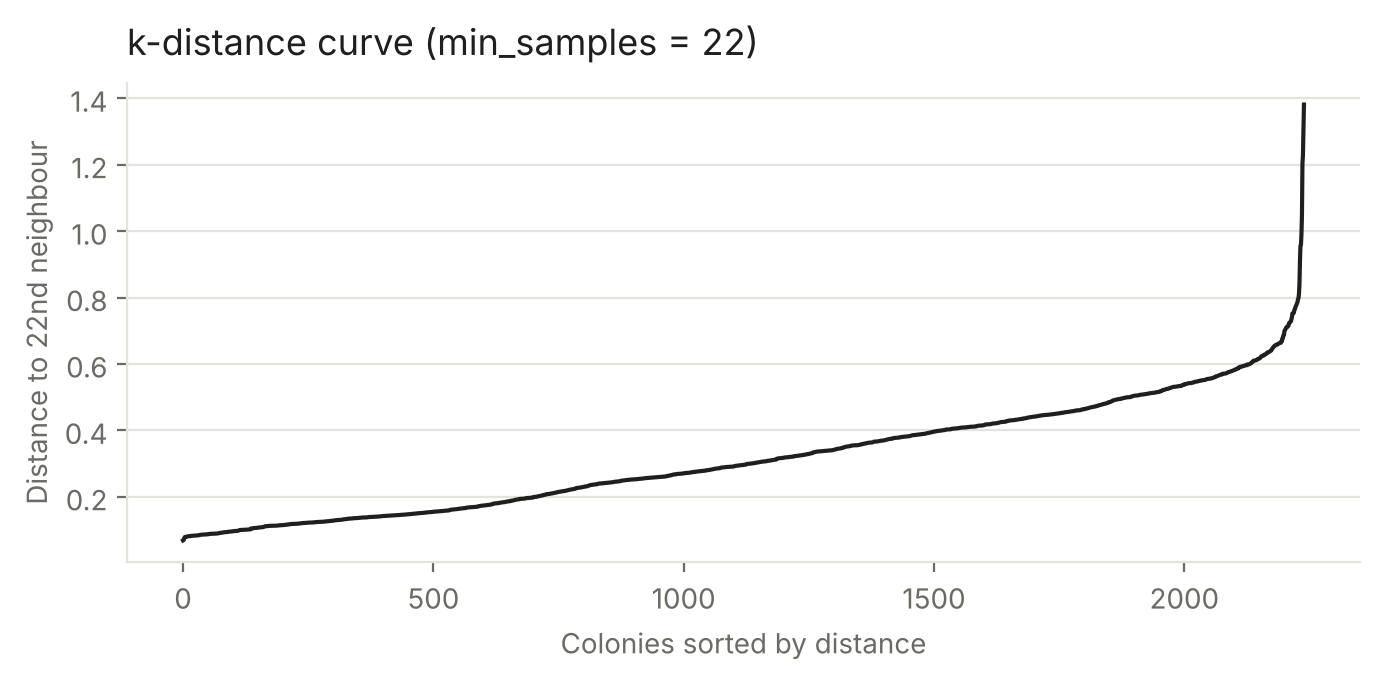

In [11]:
kd = md.k_distance(X, min_samples=22)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(kd, color=pl.INK, linewidth=1.5)
pl.style(ax); pl.title(ax, "k-distance curve (min_samples = 22)")
ax.set_xlabel("Colonies sorted by distance", color=pl.MUTED); ax.set_ylabel("Distance to 22nd neighbour", color=pl.MUTED)
pl.save(fig, "images/k_distance.png")
grid = md.dbscan_grid(X, np.round(np.arange(0.20, 0.61, 0.04), 2), [11, 22])
grid[grid.min_samples == 22][["eps", "clusters", "noise_share", "silhouette"]]

Below `eps` ≈ 0.28 DBSCAN labels most colonies as noise; above it, everything merges into **one** dense cluster. The data has no separate dense regions: the segments found in section 5 are partitions of one continuous cloud, not islands.

**Replicating the original result.** The first version of this project reported DBSCAN as the best model (silhouette 0.35, `eps = 0.5`). Re-running it with the original 12 features shows why:

In [12]:
X_original = pp.scale_for_clustering(imputed[features + ["Technological_Advancements"]])
orig = DBSCAN(eps=0.5, min_samples=5).fit_predict(X_original)
print(pd.Series(orig).value_counts().rename("colonies").to_string())
print(f"Silhouette including noise: {silhouette_score(X_original, orig):.3f}")
pd.crosstab(orig, df["Technological_Advancements"].fillna(-1).astype(int), rownames=["DBSCAN label"], colnames=["Technological_Advancements"])

 0    2071
 1      96
-1      73
Silhouette including noise: 0.343


Technological_Advancements,-1,0,1
DBSCAN label,,,
-1,6,29,38
0,206,1865,0
1,0,0,96


The small "cluster" is almost exactly the colonies with a rare high value of `Technological_Advancements`, a near-constant feature that min-max scaling turned into a large distance. The high silhouette came from that artefact plus counting noise points. Removing the feature removes the cluster.

## 7. Stability and agreement

A useful segmentation should survive resampling. Each method is refitted on 30 bootstrap samples and compared with the full-data partition using the Adjusted Rand Index (1 = identical, 0 = chance).

In [13]:
rows = []
for method in ["K-Means", "Hierarchical (Ward)", "Gaussian mixture"]:
    scores = md.bootstrap_stability(X, method, k=2, n_boot=30)
    rows.append({"method": method, "mean ARI": scores.mean(), "sd": scores.std()})
stability = pd.DataFrame(rows).set_index("method")
stability

,mean ARI,sd
method,,
K-Means,0.973,0.016
Hierarchical (Ward),0.675,0.100
Gaussian mixture,0.939,0.051


In [14]:
labels = {m: md.fit_labels(m, X, 2) for m in ["K-Means", "Hierarchical (Ward)", "Gaussian mixture"]}
pd.DataFrame([[adjusted_rand_score(labels[a], labels[b]) for b in labels] for a in labels],
             index=labels, columns=labels)

,K-Means,Hierarchical (Ward),Gaussian mixture
K-Means,1.000,0.683,0.664
Hierarchical (Ward),0.683,1.000,0.511
Gaussian mixture,0.664,0.511,1.000


K-Means is almost perfectly reproducible (ARI ≈ 0.97); Ward's tree changes noticeably with the sample (ARI ≈ 0.68). The three methods agree well with each other (ARI 0.51–0.68), so the two-group split is not an artefact of one algorithm. **K-Means with k = 2 is retained.**

## 8. The two segments

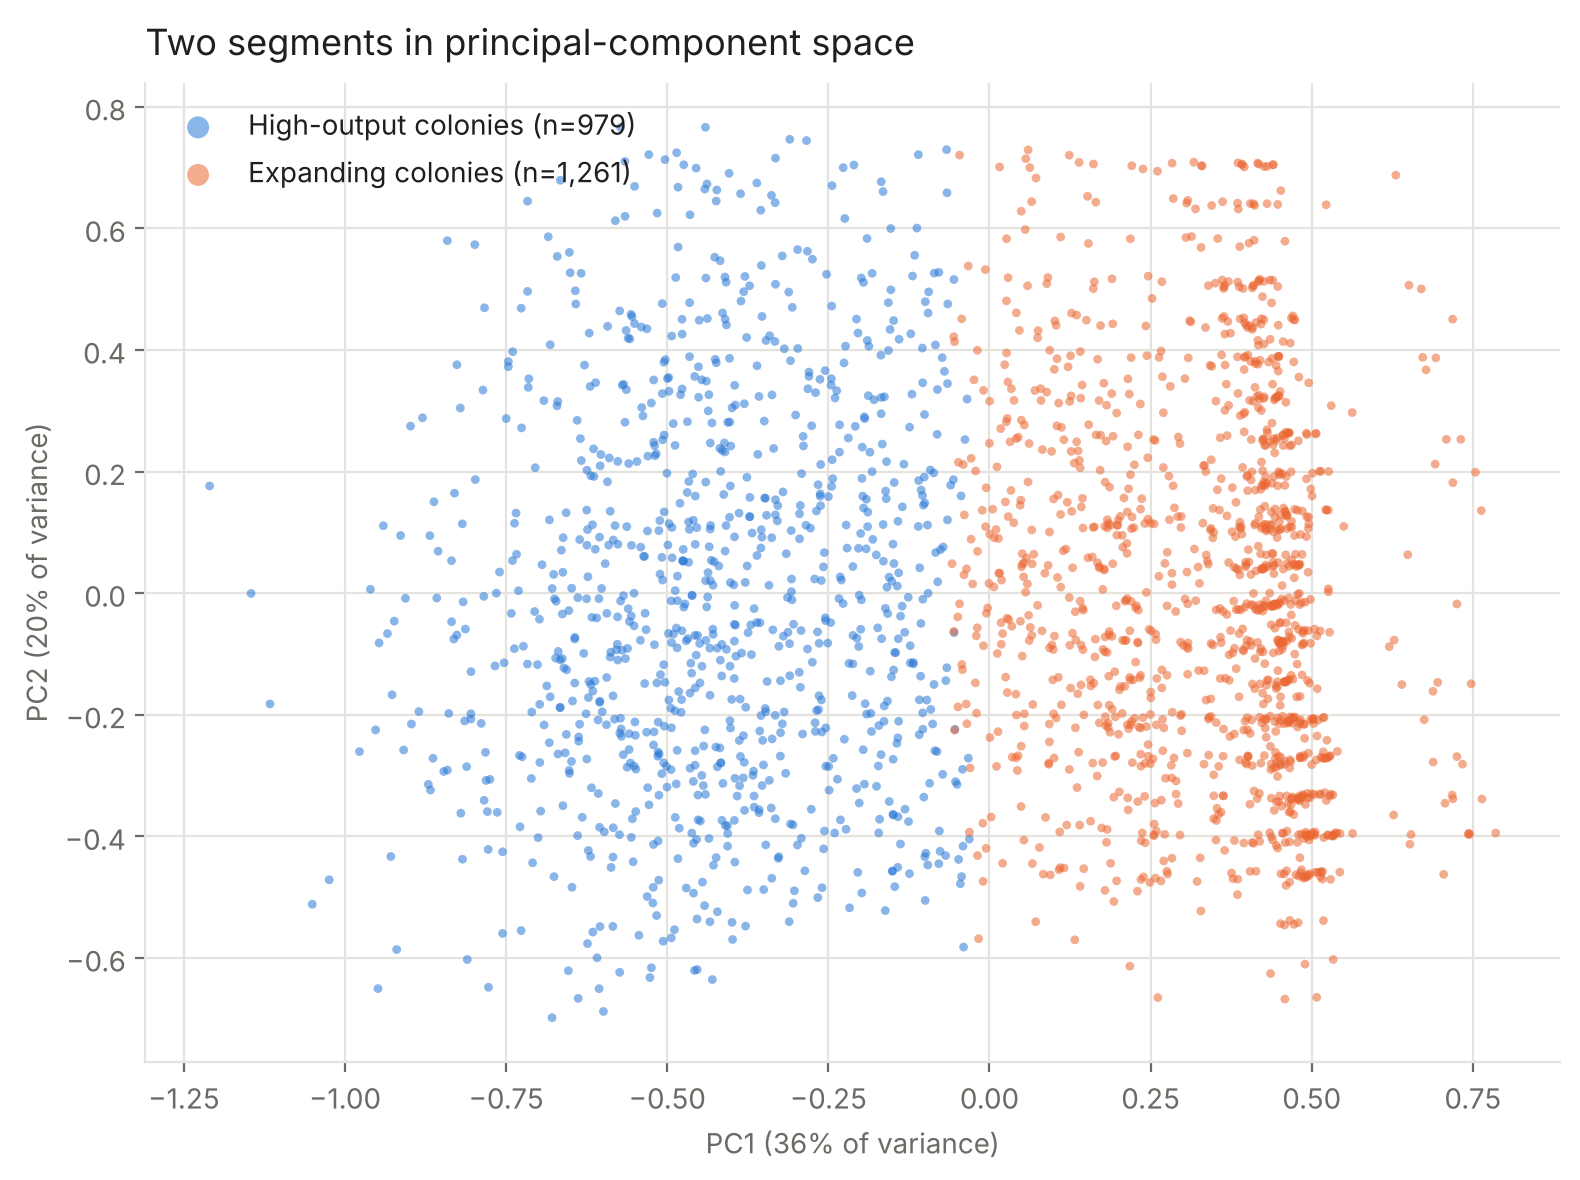

In [15]:
final = labels["K-Means"]
profile_raw = df[features].groupby(final).mean().T
high = int(profile_raw.loc["Liquid_Energy_Consumption_Terawatts"].idxmax())
names = {high: "High-output colonies", 1 - high: "Expanding colonies"}
order = [high, 1 - high]

pca = PCA(n_components=2, random_state=SEED).fit(X)
coords = pca.transform(X)
remap = np.array([order.index(l) for l in final])
pl.pca_scatter(coords, remap, pca.explained_variance_ratio_, [names[o] for o in order], path="images/segments_pca.png");

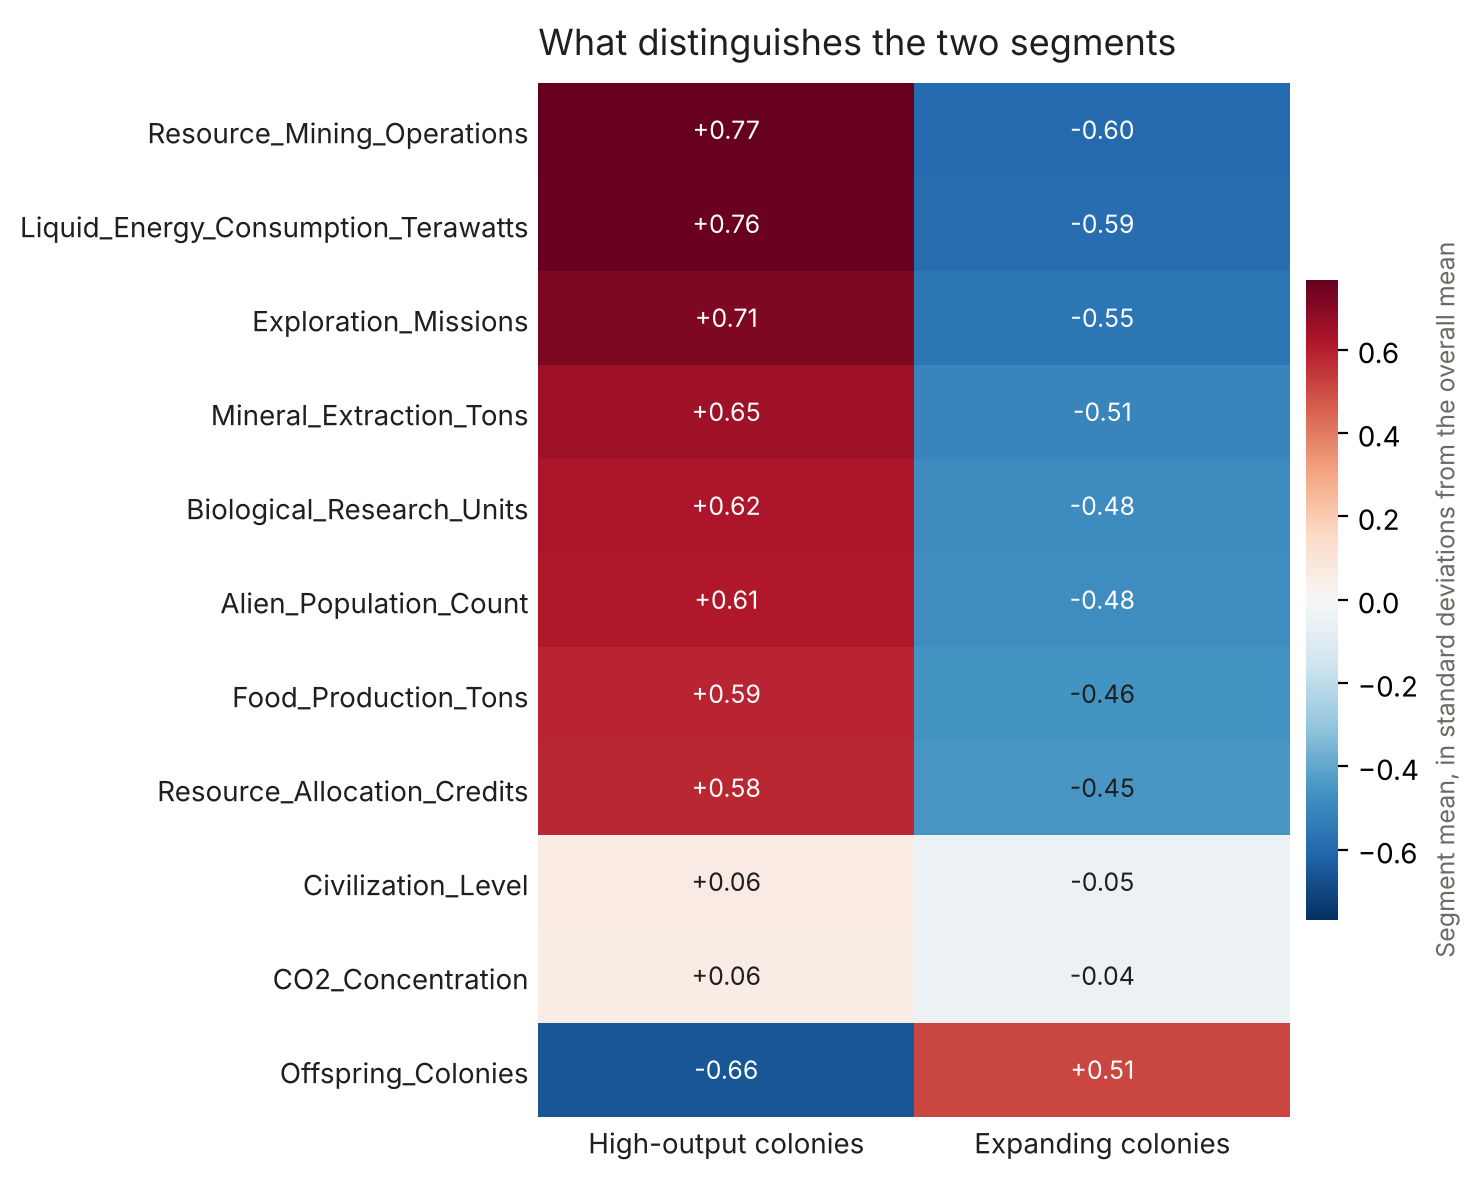

In [16]:
z = pd.DataFrame(pp.standardize(df[features]).fillna(0).groupby(final).mean().T)[order]
z.columns = [names[o] for o in order]
z = z.reindex(z.iloc[:, 0].sort_values(ascending=False).index)
pl.profile_heatmap(z, path="images/segment_profiles.png");

In [17]:
summary = profile_raw[order].copy()
summary.columns = [names[o] for o in order]
summary["ratio"] = summary.iloc[:, 0] / summary.iloc[:, 1]
summary.loc["Share of colonies"] = [np.mean(final == o) for o in order] + [np.nan]
summary

,High-output colonies,Expanding colonies,ratio
Food_Production_Tons,52.365,5.866,8.928
Mineral_Extraction_Tons,326.693,40.944,7.979
Resource_Mining_Operations,8.519,3.602,2.365
Resource_Allocation_Credits,52.727,6.591,7.999
CO2_Concentration,5.622,5.308,1.059
Liquid_Energy_Consumption_Terawatts,589.764,81.838,7.206
Offspring_Colonies,0.052,0.756,0.069
Biological_Research_Units,75.503,8.856,8.526
Alien_Population_Count,69851.269,38551.261,1.812
Exploration_Missions,5.003,0.851,5.876


**High-output colonies (about 44%).** Around 8–9 times the food production, mineral extraction, biological research and resource credits of the other segment, 7 times the energy consumption, about 6 times the exploration missions and 1.8 times the population. They have almost no offspring colonies.

**Expanding colonies (about 56%).** Low production and consumption across the board, but most of the offspring colonies in the dataset. Their profile is consistent with colonies that put resources into growth rather than output.

CO₂ concentration and civilization level barely differ between segments: the split is economic, not environmental or developmental.

## 9. Conclusions and limitations

1. The colonies split into **two robust segments** that every method recovers. Finer partitions (k ≥ 3) score lower on every index and are less stable.
2. Cluster structure is **moderate** (silhouette 0.28): the segments are two regions of one continuous population, which DBSCAN confirms by finding a single dense cluster.
3. **Preprocessing choices matter as much as the algorithm.** A single near-constant feature created a fake cluster and made DBSCAN look like the best model in the original analysis.
4. **Limitations.** Internal indices measure geometry, not usefulness; with no ground truth, the segments should be validated against an external outcome. KNN imputation assumes values are missing at random. Min-max scaling gives the ordinal civilization level the same weight as continuous features.